# 01 – Kraft- und Potentialkurven

**Team 1 – Physikalisches Basismodell** (Aufgabenblatt §9, Schritte 1–6)

Diese Notebook vergleicht die drei getrennten Modellmodi für zwei Protozellen mit
R = 500 nm im Oberflächenabstandsbereich L = 2–100 nm:

- **vdW-only**: nicht-retardierte Hamaker-Anziehung (Nahbereichsgrenzfall der Lifshitz-Theorie)
- **klassisches DLVO**: elektrostatische Doppelschicht-Repulsion + vdW + Core-Term
- **CL-retarded**: vdW-Grenzfall mit Retardierungsfaktor r(L) = 1/(1 + L/L_r)^p

**Wichtig (§3, Grundsatz):** vdW und CL werden nie addiert – vdW *ist* bereits der
nicht-retardierte Grenzfall des Lifshitz-Rahmens. Die Modi werden nur verglichen.

Materialklassen: Fettsäurevesikel (A_H = 0.2, 0.5, 1.0 ×10⁻²¹ J) und PMBCs
(A_H = 1, 3, 5, 10 ×10⁻²¹ J). Referenzsalz: 100 mM (Debye-Länge 0.96 nm).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.constants import DEBYE_LENGTHS, PN, kBT
from src.potentials import ProtocellForces
from src.force_table import force_table
from src.plots import setup_style, save_fig

setup_style()

In [2]:
# Parameterraum (§4): log-Gitter 2–100 nm + Stützstellen (§9, Schritt 2)
L = np.geomspace(2e-9, 100e-9, 300)
SUPPORT_NM = (2, 3, 5, 10, 20, 30, 50, 100)

# Referenzmodelle: PMBC (A_H = 5e-21 J) und Fettsäurevesikel (A_H = 0.5e-21 J),
# jeweils bei 100 mM Salz (Standard-Debye-Länge 0.96 nm)
pmbc = ProtocellForces(A_H=5e-21)
fatty = ProtocellForces(A_H=0.5e-21)

## Pflichtplot 1: Kraftkurven F(L) in pN

Alle vier Beiträge für PMBCs bei 100 mM Salz. Negative Kräfte wirken anziehend,
positive abstoßend (log-log-Achsen).

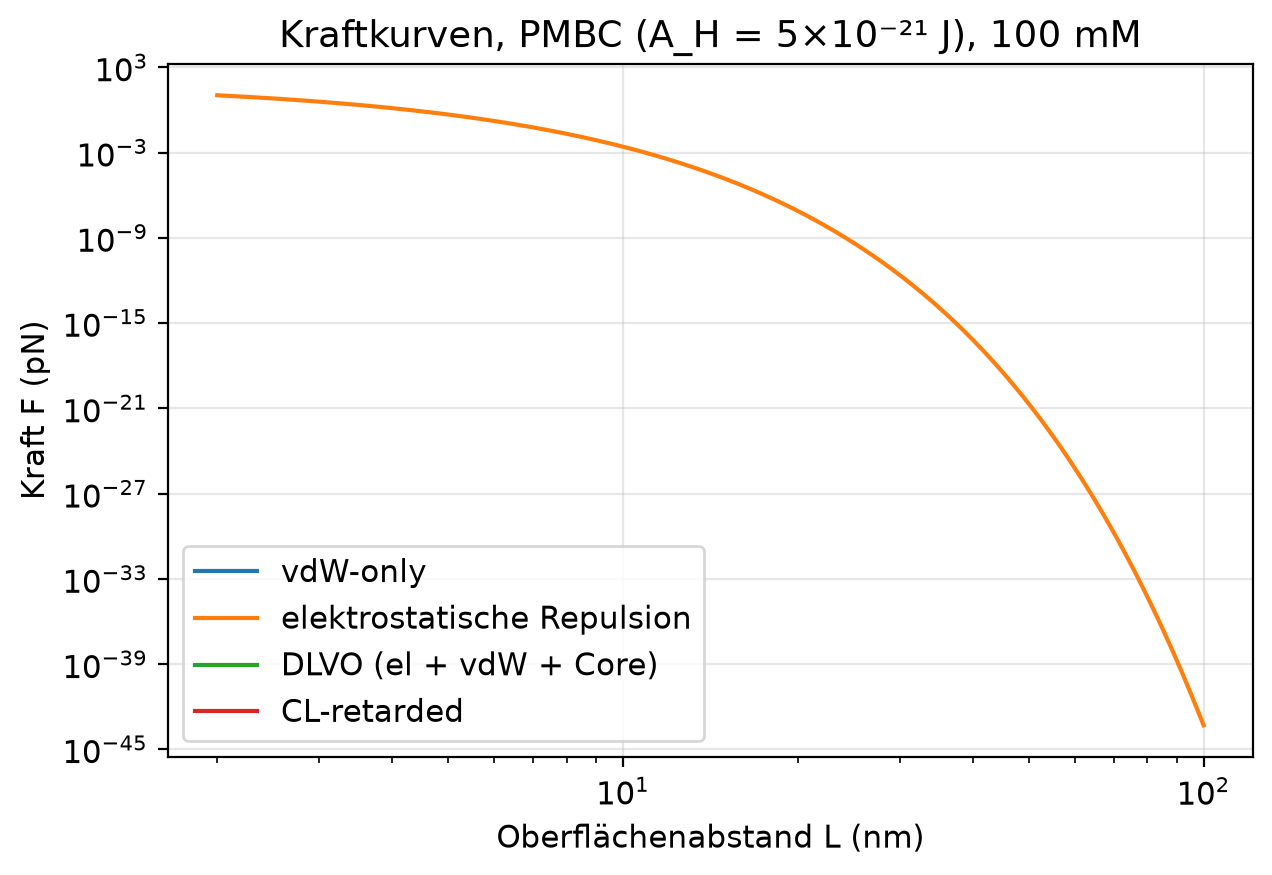

In [3]:
fig, ax = plt.subplots()
ax.loglog(L / 1e-9, pmbc.F_vdw(L) / PN, label="vdW-only")
ax.loglog(L / 1e-9, pmbc.F_el(L) / PN, label="elektrostatische Repulsion")
ax.loglog(L / 1e-9, pmbc.F_dlvo(L) / PN, label="DLVO (el + vdW + Core)")
ax.loglog(L / 1e-9, pmbc.F_cl_retarded(L) / PN, label="CL-retarded")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Oberflächenabstand L (nm)")
ax.set_ylabel("Kraft F (pN)")
ax.set_title("Kraftkurven, PMBC (A_H = 5×10⁻²¹ J), 100 mM")
ax.legend()
save_fig(fig, "01_kraftkurven_pmbc")
plt.show()

**Beobachtung:** Die elektrostatische Repulsion bricht innerhalb weniger
Debye-Längen (~1 nm) auf vernachlässigbare Werte zusammen; jenseits davon
bestimmen vdW bzw. die abgeschwächte CL-Kraft das Bild. Der Core-Term verhindert
die numerische Divergenz bei L → L_min. DLVO und CL-retarded dürfen nicht addiert
werden – sie sind alternative Beschreibungen desselben Anziehungsbereichs.

## Pflichtplot 2: Potentialkurven U(L)/kBT

Thermische Relevanz: |U| ~ kBT bedeutet, dass Brownsche Fluktuationen mit der
Wechselwirkung konkurrieren.

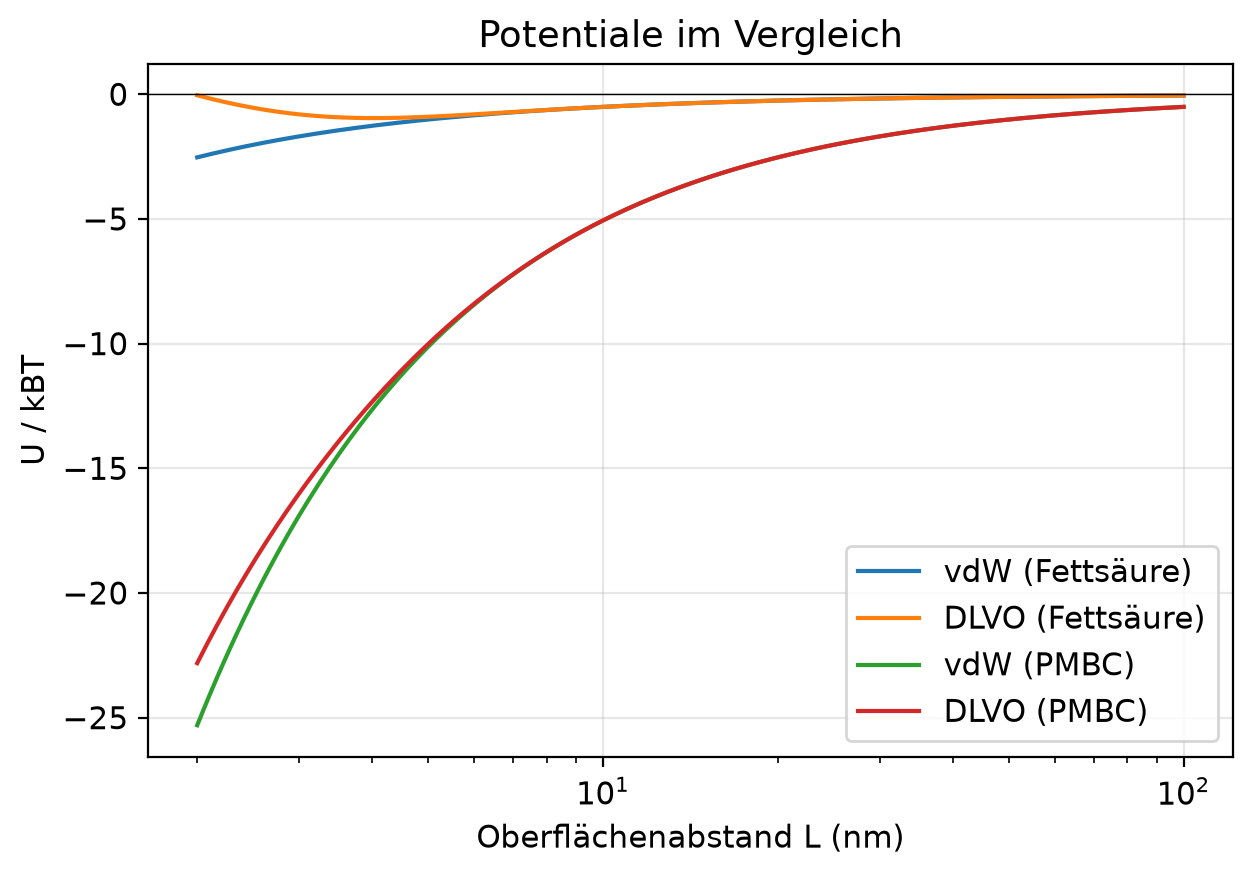

In [4]:
fig, ax = plt.subplots()
ax.semilogx(L / 1e-9, fatty.U_vdw(L) / kBT(), label="vdW (Fettsäure)")
ax.semilogx(L / 1e-9, fatty.U_dlvo(L) / kBT(), label="DLVO (Fettsäure)")
ax.semilogx(L / 1e-9, pmbc.U_vdw(L) / kBT(), label="vdW (PMBC)")
ax.semilogx(L / 1e-9, pmbc.U_dlvo(L) / kBT(), label="DLVO (PMBC)")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Oberflächenabstand L (nm)")
ax.set_ylabel("U / kBT")
ax.set_title("Potentiale im Vergleich")
ax.legend()
save_fig(fig, "02_potentiale")
plt.show()

## Pflichtplot 3: Retardierungsfaktor r(L)

r(L) = 1/(1 + L/L_r)^p schwächt die nicht-retardierte vdW-Grenze ab (§7).
Empfohlene Startwerte L_r = 20 nm, p = 2; zusätzlich L_r = 10, 20, 30 nm und
p = 1, 2.

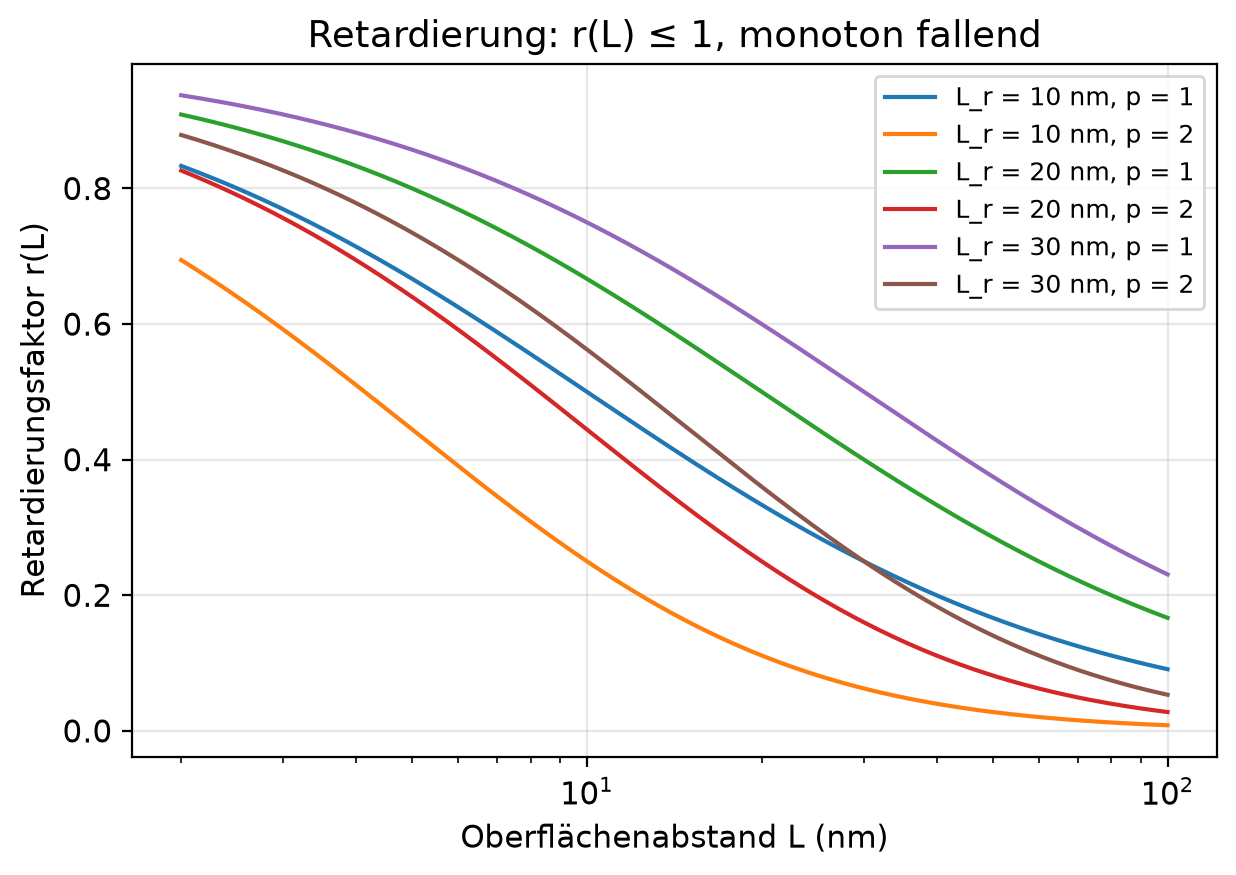

In [5]:
fig, ax = plt.subplots()
for L_ret in (10e-9, 20e-9, 30e-9):
    for p in (1, 2):
        m = ProtocellForces(A_H=5e-21, L_ret=L_ret, p_ret=p)
        ax.semilogx(
            L / 1e-9,
            m.retardation_factor(L),
            label=f"L_r = {L_ret/1e-9:.0f} nm, p = {p}",
        )
ax.set_xlabel("Oberflächenabstand L (nm)")
ax.set_ylabel("Retardierungsfaktor r(L)")
ax.set_title("Retardierung: r(L) ≤ 1, monoton fallend")
ax.legend(fontsize=9)
save_fig(fig, "03_retardierungsfaktor")
plt.show()

**Beobachtung:** Retardierung schwächt die Anziehung *ab* (§18, Fehler 4) –
je größer L_r, desto später setzt die Abschwächung ein; p kontrolliert die
Steilheit. Bei L_r = 20 nm, p = 2 bleibt bei L = 20 nm nur noch ein Viertel der
nicht-retardierten Kraft.

## Pflichtplot 4: DLVO vs. CL-retarded für Fettsäure und PMBC

Der Modellvergleich je Material: wo trägt klassische DLVO-Physik, wo die
retardierte CL-Approximation?

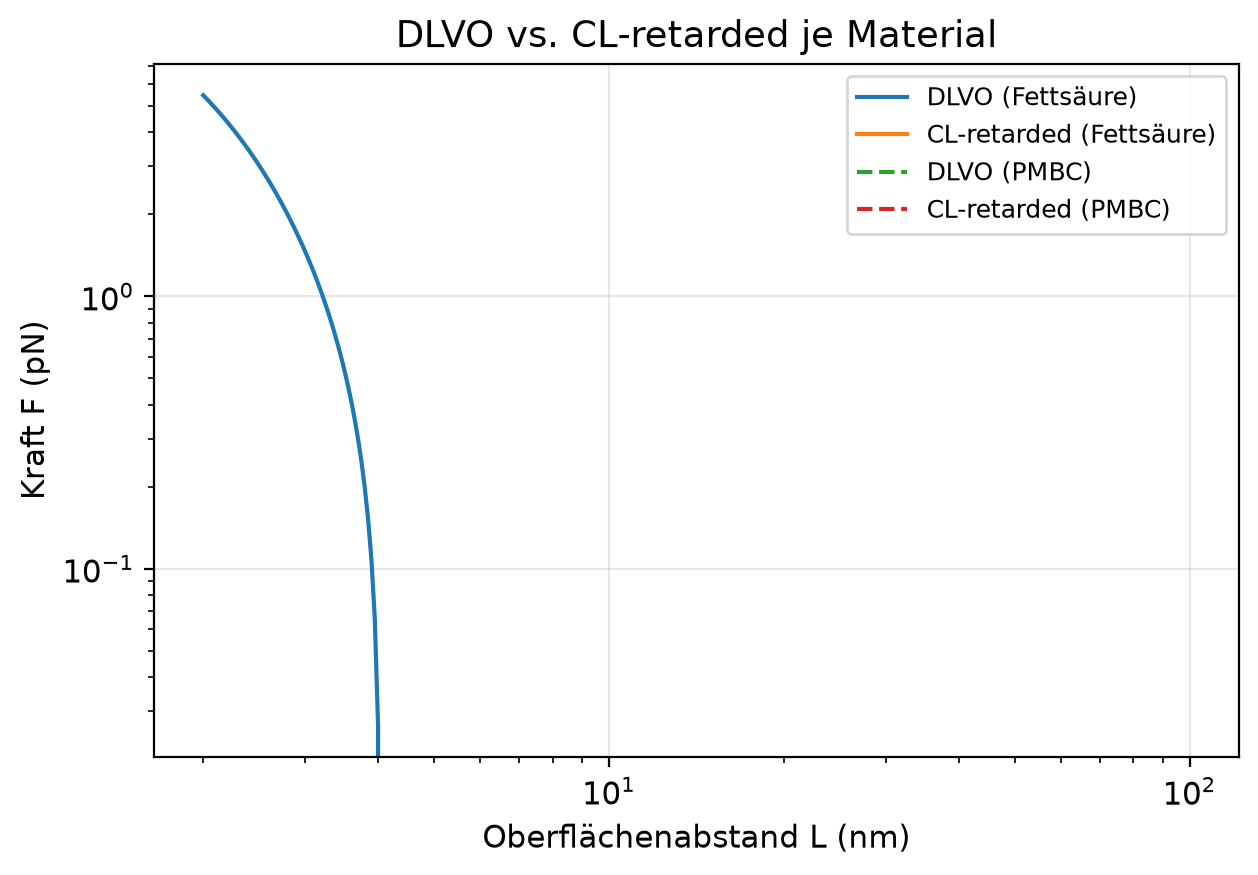

In [6]:
fig, ax = plt.subplots()
ax.loglog(L / 1e-9, fatty.F_dlvo(L) / PN, label="DLVO (Fettsäure)")
ax.loglog(L / 1e-9, fatty.F_cl_retarded(L) / PN, label="CL-retarded (Fettsäure)")
ax.loglog(L / 1e-9, pmbc.F_dlvo(L) / PN, "--", label="DLVO (PMBC)")
ax.loglog(L / 1e-9, pmbc.F_cl_retarded(L) / PN, "--", label="CL-retarded (PMBC)")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Oberflächenabstand L (nm)")
ax.set_ylabel("Kraft F (pN)")
ax.set_title("DLVO vs. CL-retarded je Material")
ax.legend(fontsize=9)
save_fig(fig, "04_dlvo_vs_cl_retarded")
plt.show()

## Salzstudie: wo verschwindet die Elektrostatik? (§9, Schritt 4)

Debye-Screening: U_el = B·exp(−κL) mit κ = 1/λ_D. Prüfung, ab welchem L die
elektrostatische Repursion praktisch (< 0.01 pN) verschwindet.

In [7]:
rows = []
for salt, lam in DEBYE_LENGTHS.items():
    m = ProtocellForces(A_H=5e-21, lambda_D=lam)
    weak = L[np.abs(m.F_el(L)) / PN < 0.01]
    rows.append({
        "Salz (mM)": salt,
        "λ_D (nm)": lam / 1e-9,
        "|F_el| < 0.01 pN ab L (nm)": weak.min() / 1e-9 if len(weak) else np.nan,
        "F_el(2 nm) (pN)": m.F_el(2e-9) / PN,
        "F_el(5 nm) (pN)": m.F_el(5e-9) / PN,
    })
salt_table = pd.DataFrame(rows)
salt_table

,Salz (mM),λ_D (nm),|F_el| < 0.01 pN ab L (nm),F_el(2 nm) (pN),F_el(5 nm) (pN)
0,50,1.36,11.852382,13.910439,1.532281
1,100,0.96,8.772344,10.678167,0.469166
2,200,0.68,6.408309,6.392967,0.077571


**Antwort auf §9 Schritt 4:** Die elektrostatische DLVO-Repulsion ist nach
wenigen Debye-Längen praktisch weg – bei 100 mM (λ_D ≈ 0.96 nm) spätestens ab
~3–4 nm, bei 50 mM ab ~4–5 nm, bei 200 mM ab ~2–3 nm. Im Bereich 5–100 nm spielt
klassische Elektrostatik für die Paardynamik praktisch keine Rolle mehr. Die
Salzabhängigkeit der *Fluktuationsbeiträge* (vdW/CL) ist dagegen nicht durch
exp(−κL) beschrieben – das ist Lifshitz-Territorium (§8-Ausblick).

## Krafttabellen an den Stützstellen

U/kBT und F in pN für alle Hamaker-Werte beider Materialklassen (§6, Materialmodell).

In [8]:
MATERIALS = {
    "Fettsäurevesikel": [0.2e-21, 0.5e-21, 1.0e-21],
    "PMBC": [1e-21, 3e-21, 5e-21, 10e-21],
}
tables = {}
for material, values in MATERIALS.items():
    for A_H in values:
        tab = force_table(ProtocellForces(A_H=A_H))
        tables[f"{material}, A_H = {A_H/1e-21:.1f}×10⁻²¹ J"] = tab

for name, tab in tables.items():
    print(f"--- {name} ---")
    display(tab.round(4))

--- Fettsäurevesikel, A_H = 0.2×10⁻²¹ J ---


,L_nm,F_vdw_pN,F_el_pN,F_dlvo_pN,F_cl_ret_pN,U_vdw_kBT,U_dlvo_kBT,retardation_factor
0,2,-2.0833,10.6782,8.5948,-1.7218,-1.0122,1.4781,0.8264
1,3,-0.9259,3.7680,2.8420,-0.7001,-0.6748,0.2039,0.7561
2,5,-0.3333,0.4692,0.1358,-0.2133,-0.4049,-0.2955,0.6400
3,10,-0.0833,0.0026,-0.0808,-0.0370,-0.2024,-0.2018,0.4444
4,20,-0.0208,0.0000,-0.0208,-0.0052,-0.1012,-0.1012,0.2500
5,30,-0.0093,0.0000,-0.0093,-0.0015,-0.0675,-0.0675,0.1600
6,50,-0.0033,0.0000,-0.0033,-0.0003,-0.0405,-0.0405,0.0816
7,100,-0.0008,0.0000,-0.0008,-0.0000,-0.0202,-0.0202,0.0278


--- Fettsäurevesikel, A_H = 0.5×10⁻²¹ J ---


,L_nm,F_vdw_pN,F_el_pN,F_dlvo_pN,F_cl_ret_pN,U_vdw_kBT,U_dlvo_kBT,retardation_factor
0,2,-5.2083,10.6782,5.4698,-4.3044,-2.5305,-0.0402,0.8264
1,3,-2.3148,3.7680,1.4531,-1.7503,-1.6870,-0.8083,0.7561
2,5,-0.8333,0.4692,-0.3642,-0.5333,-1.0122,-0.9028,0.6400
3,10,-0.2083,0.0026,-0.2058,-0.0926,-0.5061,-0.5055,0.4444
4,20,-0.0521,0.0000,-0.0521,-0.0130,-0.2531,-0.2531,0.2500
5,30,-0.0231,0.0000,-0.0231,-0.0037,-0.1687,-0.1687,0.1600
6,50,-0.0083,0.0000,-0.0083,-0.0007,-0.1012,-0.1012,0.0816
7,100,-0.0021,0.0000,-0.0021,-0.0001,-0.0506,-0.0506,0.0278


--- Fettsäurevesikel, A_H = 1.0×10⁻²¹ J ---


,L_nm,F_vdw_pN,F_el_pN,F_dlvo_pN,F_cl_ret_pN,U_vdw_kBT,U_dlvo_kBT,retardation_factor
0,2,-10.4167,10.6782,0.2615,-8.6088,-5.0611,-2.5708,0.8264
1,3,-4.6296,3.7680,-0.8617,-3.5007,-3.3740,-2.4953,0.7561
2,5,-1.6667,0.4692,-1.1975,-1.0667,-2.0244,-1.9150,0.6400
3,10,-0.4167,0.0026,-0.4141,-0.1852,-1.0122,-1.0116,0.4444
4,20,-0.1042,0.0000,-0.1042,-0.0260,-0.5061,-0.5061,0.2500
5,30,-0.0463,0.0000,-0.0463,-0.0074,-0.3374,-0.3374,0.1600
6,50,-0.0167,0.0000,-0.0167,-0.0014,-0.2024,-0.2024,0.0816
7,100,-0.0042,0.0000,-0.0042,-0.0001,-0.1012,-0.1012,0.0278


... (4 outputs left out)

--- PMBC, A_H = 5.0×10⁻²¹ J ---


,L_nm,F_vdw_pN,F_el_pN,F_dlvo_pN,F_cl_ret_pN,U_vdw_kBT,U_dlvo_kBT,retardation_factor
0,2,-52.0833,10.6782,-41.4052,-43.0441,-25.3053,-22.8150,0.8264
1,3,-23.1481,3.7680,-19.3802,-17.5033,-16.8702,-15.9914,0.7561
2,5,-8.3333,0.4692,-7.8642,-5.3333,-10.1221,-10.0127,0.6400
3,10,-2.0833,0.0026,-2.0808,-0.9259,-5.0611,-5.0605,0.4444
4,20,-0.5208,0.0000,-0.5208,-0.1302,-2.5305,-2.5305,0.2500
5,30,-0.2315,0.0000,-0.2315,-0.0370,-1.6870,-1.6870,0.1600
6,50,-0.0833,0.0000,-0.0833,-0.0068,-1.0122,-1.0122,0.0816
7,100,-0.0208,0.0000,-0.0208,-0.0006,-0.5061,-0.5061,0.0278


--- PMBC, A_H = 10.0×10⁻²¹ J ---


,L_nm,F_vdw_pN,F_el_pN,F_dlvo_pN,F_cl_ret_pN,U_vdw_kBT,U_dlvo_kBT,retardation_factor
0,2,-104.1667,10.6782,-93.4885,-86.0882,-50.6105,-48.1202,0.8264
1,3,-46.2963,3.7680,-42.5283,-35.0067,-33.7403,-32.8616,0.7561
2,5,-16.6667,0.4692,-16.1975,-10.6667,-20.2442,-20.1348,0.6400
3,10,-4.1667,0.0026,-4.1641,-1.8519,-10.1221,-10.1215,0.4444
4,20,-1.0417,0.0000,-1.0417,-0.2604,-5.0611,-5.0611,0.2500
5,30,-0.4630,0.0000,-0.4630,-0.0741,-3.3740,-3.3740,0.1600
6,50,-0.1667,0.0000,-0.1667,-0.0136,-2.0244,-2.0244,0.0816
7,100,-0.0417,0.0000,-0.0417,-0.0012,-1.0122,-1.0122,0.0278


## Interpretation (streng nach §10)

- **2–5 nm:** Elektrostatik kann netto dominieren (salzabhängig); Core-Term wichtig; vdW/CL stark, aber nahbereichsempfindlich.
- **5–10 nm:** Elektrostatik stark reduziert – Übergangsbereich; PMBCs können noch relevante Anziehung zeigen (U bis einige kBT).
- **10–30 nm:** DLVO-Elektrostatik praktisch weg; vdW/CL schwach bis moderat – für PMBCs plausibel, für Fettsäure grenzwertig.
- **30–100 nm:** Einzelpaar-Kräfte beider Modelle klein; robuste Clusterbildung erfordert Mehrkörper-, Geometrie- oder Gap-Effekte.

Standard-Lifshitz-/CL-Kopplung kann im Bereich 2–30 nm plausibel zur Stabilisierung
beitragen, besonders für PMBC-artige Protozellen. **Nicht behauptet wird**, dass CL
die Clusterbildung von 2–100 nm vollständig erklärt.